# Exploratory Data Analysis (EDA)

## Project: E-commerce Returns & Customer Behavior Analysis

### Objective
To explore the cleaned dataset, identify patterns, and generate insights into customer behavior, sales, delivery performance, and returns.

### Dataset
Cleaned datasets are stored in `data/processed/`.

### Analysis Approach
- Descriptive Analysis
- Diagnostic Analysis
- Univariate, Bivariate & Multivariate Analysis
- Business-focused Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
orders = pd.read_csv("../data/processed/orders_cleaned.csv")
orders_items = pd.read_csv("../data/processed/orders_items_cleaned.csv")
deliveries = pd.read_csv("../data/processed/deliveries_cleaned.csv")
customers = pd.read_csv("../data/processed/customers_cleaned.csv")
products = pd.read_csv("../data/processed/products_cleaned.csv")
returns = pd.read_csv("../data/processed/returns_cleaned.csv")
warehouses = pd.read_csv("../data/processed/warehouses_cleaned.csv")

In [3]:
datasets = {
    "Orders": orders,
    "Order Items": orders_items,
    "Deliveries": deliveries,
    "Customers": customers,
    "Products": products,
    "Returns": returns,
    "Warehouses": warehouses
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Orders: (1000000, 6)
Order Items: (1666691, 6)
Deliveries: (799835, 4)
Customers: (50000, 7)
Products: (300, 6)
Returns: (299404, 6)
Warehouses: (4, 3)


In [4]:
orders["order_status"].value_counts()

order_status
Delivered    799835
Cancelled    200165
Name: count, dtype: int64

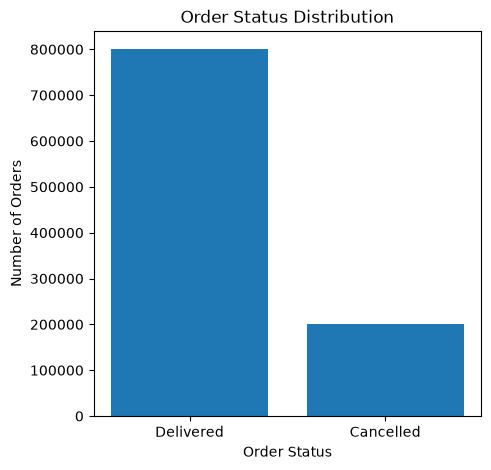

In [5]:
status_counts = orders["order_status"].value_counts()

plt.figure(figsize=(5, 5))
plt.bar(status_counts.index, status_counts.values)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")

plt.show()

### Business Question 2: Payment Method vs Order Status

**Objective:** To compare delivered and cancelled orders across different payment methods.

**Analysis Type:** Descriptive Analysis

**Business Purpose:** To identify which payment methods have a higher number of cancelled orders.

In [6]:
# Compare order status across different payment methods
payment_status = pd.crosstab(
    orders["payment_method"],
    orders["order_status"]
)

# Display the summary
payment_status

order_status,Cancelled,Delivered
payment_method,,
Cash on Delivery,40001,160115
Credit Card,39971,159925
Debit Card,40066,160239
Net Banking,40009,159943
UPI,40118,159613


In [7]:
# Calculate order status percentage for each payment method
payment_percentage = pd.crosstab(
    orders["payment_method"],
    orders["order_status"],
    normalize="index"
) * 100

# Display percentage rounded to 2 decimal places
payment_percentage.round(2)

order_status,Cancelled,Delivered
payment_method,,
Cash on Delivery,19.99,80.01
Credit Card,20.00,80.00
Debit Card,20.00,80.00
Net Banking,20.01,79.99
UPI,20.09,79.91


**Key Observation:**

UPI has the highest cancellation count among the payment methods. However, cancellation counts are very close across all payment methods.

To make a fair comparison, cancellation percentages are calculated using the total orders for each payment method. This helps identify whether any payment method has a noticeably higher cancellation rate.

### Business Question 3: Product Category vs Returns

**Objective:** To identify which product categories have the highest number of returned items.

**Analysis Type:** Descriptive Analysis

**Business Purpose:** To understand return patterns across product categories and identify categories that may need further investigation.

In [8]:
# Connect returns with order items using order_item_id
returns_items = returns.merge(
    orders_items[["order_item_id", "product_id"]],
    on="order_item_id",
    how="left"
)

In [9]:
# Add product category using product_id
returns_products = returns_items.merge(
    products[["product_id", "category"]],
    on="product_id",
    how="left"
)

In [10]:
# Count return records for each product category
category_returns = returns_products["category"].value_counts()

category_returns

category
Beauty            81533
Electronics       75786
Home & Kitchen    75218
Apparel           65916
Name: count, dtype: int64

In [11]:
# Count return records where product category is missing
returns_products["category"].isna().sum()

# here 951 missing becasue of P9999 product_id which is not present in products dataset. This product id is present in returns dataset. So, we can ignore these missing values for our analysis.

np.int64(951)

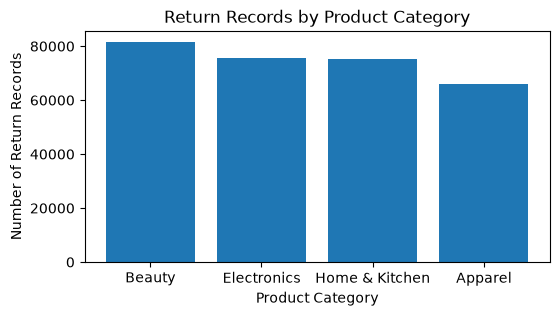

In [12]:
# Visualize return records by product category
plt.figure(figsize=(6, 3))

plt.bar(category_returns.index, category_returns.values)

plt.title("Return Records by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Return Records")

plt.show()

### Business Question 4: Product Category-wise Return Rate

**Objective:** To compare the return rate across product categories.

**Analysis Type:** Descriptive Analysis

**Business Purpose:** To identify which product categories have a higher proportion of returned items compared to the total items sold.

**Analysis Approach:**

To calculate category-wise return rate, we will compare the total quantity sold with the total quantity returned for each product category.

The calculation will use the `quantity` column from `orders_items` and the `return_quantity` column from `returns`.

In [13]:
# Add product category to order items
items_products = orders_items.merge(
    products[["product_id", "category"]],
    on="product_id",
    how="left"
)

# Calculate total quantity sold in each category
category_sold = items_products.groupby("category")["quantity"].sum()

category_sold

category
Apparel           781938
Beauty            966606
Electronics       898797
Home & Kitchen    897134
Name: quantity, dtype: int64

In [14]:
# Merge returns with order items to get product_id
returns_items = returns.merge(
    orders_items[["order_item_id", "product_id"]],
    on="order_item_id",
    how="left"
)

# Add product category
returns_products = returns_items.merge(
    products[["product_id", "category"]],
    on="product_id",
    how="left"
)

# Calculate total returned quantity by category
category_returned = returns_products.groupby("category")["return_quantity"].sum()

category_returned

category
Apparel           110396
Beauty            136487
Electronics       127713
Home & Kitchen    125984
Name: return_quantity, dtype: int64

In [15]:
# Calculate return rate for each product category
category_return_rate = (
    category_returned / category_sold
) * 100

# Display return rate rounded to 2 decimal places
category_return_rate.round(2)

category
Apparel           14.12
Beauty            14.12
Electronics       14.21
Home & Kitchen    14.04
dtype: float64

**Key Observation:**

Electronics has the highest return rate (14.21%), while Home & Kitchen has the lowest (14.04%).

Return rates are nearly similar across all product categories, with only a small difference of 0.17 percentage points.

**Conclusion:** No substantial difference in return rates was observed across product categories. These rates are based on returned quantity divided by sold quantity.

## Business Question 5: Customer Return Behavior & Repeated Return Reasons

**Business Question**
Which customers repeatedly select the same return reason, and how does their return activity compare with their total order history?

**Objective**
To analyze customer-level return patterns by examining repeated return reasons, total orders, return records, and returned order rate.

**Analysis Type**
Descriptive and Diagnostic Analysis

**Business Purpose**
To identify customer return patterns that may require further review and understand the reasons frequently selected during product returns.


In [16]:
# Step 1: Connect return records with order items
returns_with_orders = returns.merge(
    orders_items[["order_item_id", "order_id"]],
    on="order_item_id",
    how="left"
)

# Step 2: Connect order items with order details
returns_with_customers = returns_with_orders.merge(
    orders[["order_id", "customer_id"]],
    on="order_id",
    how="left"
)

# Step 3: Connect customer IDs with customer details
returns_with_customers = returns_with_customers.merge(
    customers[["customer_id"]],
    on="customer_id",
    how="left"
)

returns_with_customers.head()

,return_id,order_item_id,return_date,return_reason,return_quantity,refund_amount,order_id,customer_id
0,RET0000001,OI00922125,2024-02-05,Changed Mind,1,823.80,ORD0553462,CUST011916
1,RET0000002,OI00255637,2024-03-08,Not As Described,3,5492.85,ORD0153444,CUST025774
2,RET0000003,OI00368545,2024-03-31,Unknown,1,293.44,ORD0221221,CUST029082
3,RET0000004,OI01504833,2024-04-16,Wrong Item,1,1960.22,ORD0902719,CUST007902
4,RET0000005,OI00029503,2024-02-11,Damaged,1,501.64,ORD0017705,CUST038886


In [ ]:
# Count return records for each customer
customer_return_count = (
    returns_with_customers
    .groupby("customer_id")["return_id"]
    .count()
    .sort_values(ascending=False)
)

# Display the 10 customers with the highest return counts
customer_return_count.head(10)



customer_id
CUST019440    22
CUST042451    21
CUST013257    20
CUST007176    20
CUST028345    19
CUST014437    19
CUST048343    19
CUST005222    18
CUST041450    18
CUST045574    18
Name: return_id, dtype: int64

### Key Observation

The customer-level return count analysis identified customers with the highest number of return records.
Customer `CUST019440` had the highest return count, with 22 return records.
However, return count alone does not indicate a higher return tendency because customers may differ in their total number of purchases.

In [22]:
# Count how often each customer selects each return reason
customer_reason_count = (
    returns_with_customers
    .groupby(["customer_id", "return_reason"])
    ["return_id"]
    .count()
    .reset_index(name="reason_count")
)

# Sort to find repeated customer-reason combinations
customer_reason_count = customer_reason_count.sort_values(
    "reason_count",
    ascending=False
)

customer_reason_count.head(15)

,customer_id,return_reason,reason_count
8947,CUST002394,Wrong Item,9
132501,CUST035364,Unknown,8
91582,CUST024408,Unknown,7
98581,CUST026271,Unknown,7
104510,CUST027848,Size Issue,7
119080,CUST031763,Wrong Item,7
56337,CUST015050,Size Issue,7
69684,CUST018606,Wrong Item,7
106972,CUST028505,Size Issue,7
95928,CUST025570,Size Issue,7


### Key Observation

The analysis identified customers who repeatedly selected the same return reason.

For example, customer `CUST002394` selected "Wrong Item" 9 times, while customer `CUST035364` selected "Unknown" 8 times.

Repeated reasons provide an additional view of customer return behavior beyond total return count.

In [24]:
# Total distinct orders placed by each customer
customer_orders = (
    orders.groupby("customer_id")["order_id"]
    .nunique()
    .rename("total_orders")
)

# Total return records and distinct returned orders per customer
customer_returns = (
    returns_with_customers
    .groupby("customer_id")
    .agg(
        total_return_records=("return_id", "count"),
        returned_orders=("order_id", "nunique")
    )
)

# Combine order and return summaries
customer_summary = pd.concat(
    [customer_orders, customer_returns],
    axis=1
).fillna(0)

# Calculate the percentage of orders that had at least one return
customer_summary["returned_order_rate"] = (
    customer_summary["returned_orders"]
    / customer_summary["total_orders"]
    * 100
)

customer_summary.head()

,total_orders,total_return_records,returned_orders,returned_order_rate
customer_id,,,,
CUST000001,12,1.0,1.0,8.333333
CUST000002,21,10.0,9.0,42.857143
CUST000003,15,3.0,2.0,13.333333
CUST000004,30,7.0,6.0,20.000000
CUST000005,19,7.0,6.0,31.578947


### Key Observation

Customer-level return rates varied across the sample customers.
For example, customer `CUST000002` had 9 returned orders out of 21 total orders, resulting in a returned order rate of 42.86%.
This comparison provides more context than return count alone.

In [25]:
# Add total orders and return activity to each customer-reason combination
customer_reason_analysis = customer_reason_count.merge(
    customer_summary,
    on="customer_id",
    how="left"
)

# Show customers who repeatedly selected the same reason
customer_reason_analysis.sort_values(
    "reason_count",
    ascending=False
).head(15)

,customer_id,return_reason,reason_count,total_orders,total_return_records,returned_orders,returned_order_rate
0,CUST002394,Wrong Item,9,23,14.0,12.0,52.173913
1,CUST035364,Unknown,8,33,15.0,11.0,33.333333
2,CUST024408,Unknown,7,27,9.0,8.0,29.629630
3,CUST026271,Unknown,7,24,12.0,10.0,41.666667
4,CUST027848,Size Issue,7,19,14.0,12.0,63.157895
5,CUST031763,Wrong Item,7,33,14.0,12.0,36.363636
6,CUST015050,Size Issue,7,24,14.0,10.0,41.666667
7,CUST018606,Wrong Item,7,26,16.0,14.0,53.846154
8,CUST028505,Size Issue,7,21,14.0,12.0,57.142857
9,CUST025570,Size Issue,7,24,10.0,9.0,37.500000


### Key Observation

The combined analysis showed that some customers repeatedly selected the same return reason and also had a relatively high returned order rate.

For example, customer `CUST027848` selected "Size Issue" 7 times and had a returned order rate of 63.16%.
These patterns can be used to create a preliminary customer review list.
However, repeated return reasons and high return rates do not confirm fraudulent behavior. Genuine product or fulfillment issues may also lead to repeated returns.

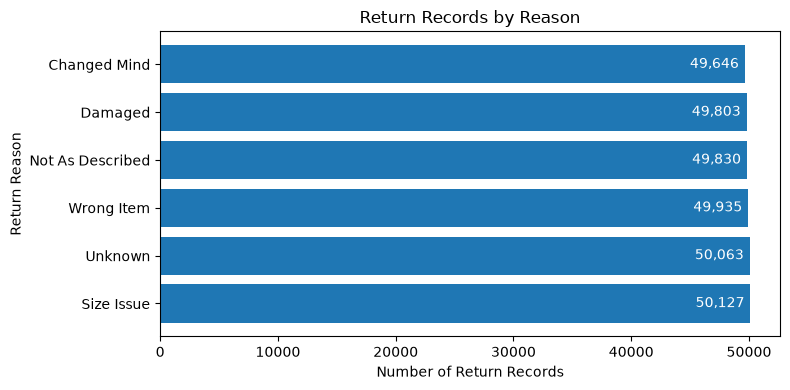

In [33]:
plt.figure(figsize=(8, 4))

plt.barh(reason_counts.index, reason_counts.values)

# Add count labels inside the bars
for bar in plt.gca().patches:
    count = int(bar.get_width())

    plt.text(
        bar.get_width() - 500,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,}",
        va="center",
        ha="right",
        color="white"
    )

plt.title("Return Records by Reason")
plt.xlabel("Number of Return Records")
plt.ylabel("Return Reason")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

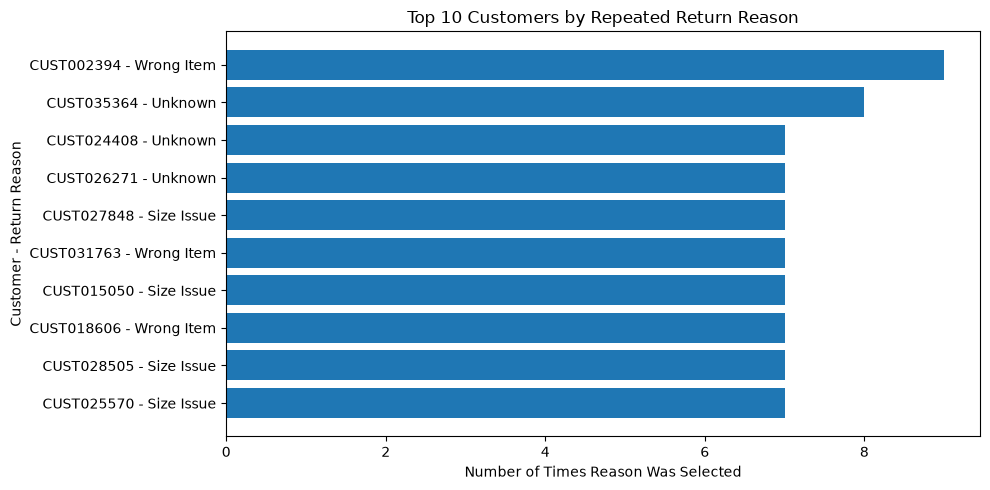

In [26]:
# Select the top 10 customer-reason combinations
top_customer_reasons = (
    customer_reason_analysis
    .sort_values("reason_count", ascending=False)
    .head(10)
)

# Create a readable label using customer ID and return reason
labels = (
    top_customer_reasons["customer_id"]
    + " - "
    + top_customer_reasons["return_reason"]
)

# Plot repeated return reasons
plt.figure(figsize=(10, 5))

plt.barh(
    labels,
    top_customer_reasons["reason_count"]
)

plt.title("Top 10 Customers by Repeated Return Reason")
plt.xlabel("Number of Times Reason Was Selected")
plt.ylabel("Customer - Return Reason")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [36]:
reason_quantity = (
    returns.groupby("return_reason")["return_quantity"]
    .sum()
    .sort_values(ascending=False)
)

reason_quantity

return_reason
Size Issue          84065
Damaged             83966
Unknown             83886
Wrong Item          83621
Not As Described    83381
Changed Mind        83236
Name: return_quantity, dtype: int64

### Q6. Monthly Return Behavior

**Business Question:** How does the return rate change over time?

**Objective:** To analyze monthly orders, returned orders, and return rate.


In [39]:
orders["order_date"] = pd.to_datetime(orders["order_date"])

In [50]:
monthly_orders = (
    orders.groupby(orders["order_date"].dt.to_period("M"))["order_id"]
    .nunique()
    .reset_index(name="total_orders")
)

monthly_orders

,order_date,total_orders
0,2024-01,157531
1,2024-02,147513
2,2024-03,157049
3,2024-04,152190
4,2024-05,157013
5,2024-06,151796
6,2024-07,76057
7,2024-08,169
8,2024-09,185
9,2024-10,163


In [51]:
returns_with_orders = (
    returns.merge(
        orders_items[["order_item_id", "order_id"]],
        on="order_item_id",
        how="left"
    )
    .merge(
        orders[["order_id", "order_date"]],
        on="order_id",
        how="left"
    )
)


monthly_returned_orders = (
    returns_with_orders.groupby(
        returns_with_orders["order_date"].dt.to_period("M")
    )["order_id"]
    .nunique()
    .reset_index(name="returned_orders")
)

monthly_returned_orders

,order_date,returned_orders
0,2024-01,43284
1,2024-02,40319
2,2024-03,43115
3,2024-04,41483
4,2024-05,42874
5,2024-06,41506
6,2024-07,20750
7,2024-08,50
8,2024-09,59
9,2024-10,54


In [52]:
monthly_return_analysis = monthly_orders.merge(
    monthly_returned_orders,
    on="order_date",
    how="left"
)

monthly_return_analysis["monthly_return_rate"] = (
    monthly_return_analysis["returned_orders"]
    / monthly_return_analysis["total_orders"]
    * 100
)

monthly_return_analysis

,order_date,total_orders,returned_orders,monthly_return_rate
0,2024-01,157531,43284,27.476497
1,2024-02,147513,40319,27.332506
2,2024-03,157049,43115,27.453215
3,2024-04,152190,41483,27.257376
4,2024-05,157013,42874,27.306019
5,2024-06,151796,41506,27.343277
6,2024-07,76057,20750,27.282170
7,2024-08,169,50,29.585799
8,2024-09,185,59,31.891892
9,2024-10,163,54,33.128834


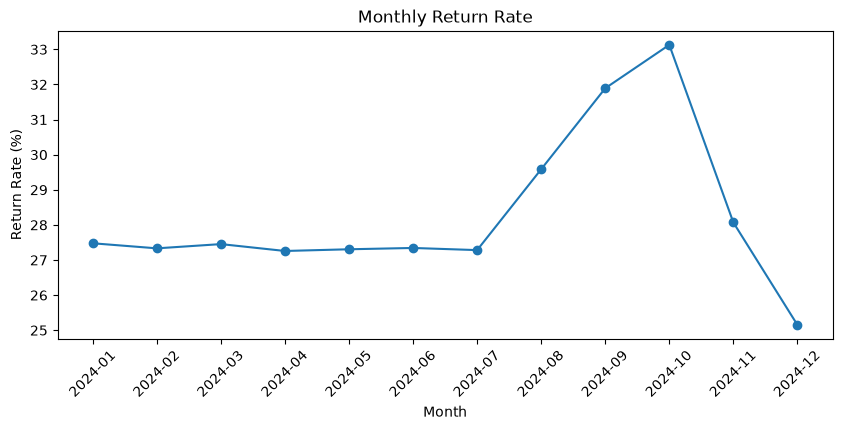

In [53]:
plt.figure(figsize=(10, 4))

plt.plot(
    monthly_return_analysis["order_date"].astype(str),
    monthly_return_analysis["monthly_return_rate"],
    marker="o"
)

plt.title("Monthly Return Rate")
plt.xlabel("Month")
plt.ylabel("Return Rate (%)")
plt.xticks(rotation=45)

plt.show()

### Key Observation

Monthly return rate remained relatively stable at around 27.3% from January to July 2024. A higher return rate was observed during August–October, but monthly order volume was extremely low during this period.

### Business Insight

Monthly return rate can help monitor return behavior over time. However, the unusual decline in order volume after July should be considered before interpreting the later monthly percentages. The trend should not be treated as a confirmed change in customer behavior without further validation.